# ME249 Fall 2026 - Project 2 - Task 2.2
**Genetic algorithm fit of the three-constant model  q" = n1 (Tw - Tsat)^n2 g^n3  (Eq. 1.1), 45 data points (P = 5.5 kPa, gamma = 1.79)**

* Cell 1: CodeP2.1F26 (data, corrected values).
* Cell 2: CodeP2.2F26 (genetic algorithm) placed in a function `run_GA` - see the header for the list of modifications (including the fix of the `import random` bug).
* Cell 3: figure style (added).
* Cell 4: first run with the skeleton initial guesses and skeleton plot.
* Cell 5: independent deterministic minimisation of the same objective (reference used only to assess the GA result).
* Cell 6: study of the initial guesses / mutation amplitude / NGEN.
* Cell 7: best fit, predicted-vs-measured plot and rms deviation.
* Cell 8: convergence histories and error landscape.

In [1]:
'''>>>>> start CodeP2.1F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Task 2.1 / 2.2:
      - two data values corrected to match the Appendix listing of the project
        statement: row 0  q" 44.2 -> 44.1 W/cm2,  row 6  superheat 37.8 -> 37.5 C
      - everything else unchanged (red data with P other than 5.5 kPa still
        commented out, ND = NS = 45)'''

# version 3 print function
from __future__ import print_function
# seed the pseudorandom number generator
from random import random
from random import seed
# seed random number generator
seed(1)

#import math and numpy packages
import math
import numpy

%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 8] # for square canvas


#import copy
from copy import copy, deepcopy


#create arrays
ydata = []
lydata = []

#Parameters for Evolution Loop
#set data parameters
ND = 45       #number of data vectors in array
DI = 5        #number of data items in vector
NS = 45       #total number of DNA strands

# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
# this is an array that is essentially a list of lists

#assembling data array
#store array where rows are data vectors
#[heat flux, superheat, gravity, surface tension parameter, pressure]

ydata =     [[44.1, 32.5, 0.098, 1.79, 5.5]]    # corrected (was 44.2)
ydata.append([47.4, 33.2, 0.098, 1.79, 5.5])
ydata.append([49.4, 34.2, 0.098, 1.79, 5.5])

ydata.append([59.2, 34.8, 0.098, 1.79, 5.5])
ydata.append([67.8, 36.3, 0.098, 1.79, 5.5])
ydata.append([73.6, 37.3, 0.098, 1.79, 5.5])
ydata.append([76.3, 37.5, 0.098, 1.79, 5.5])     # corrected (was 37.8)
ydata.append([85.3, 39.2, 0.098, 1.79, 5.5])
ydata.append([96.5, 39.3, 0.098, 1.79, 5.5])
ydata.append([111., 42.3, 0.098, 1.79, 5.5])
ydata.append([124., 43.5, 0.098, 1.79, 5.5])
ydata.append([136.2, 45.4, 0.098, 1.79, 5.5])

ydata.append([143.5, 46.7, 0.098, 1.79, 5.5])
ydata.append([154.6, 47.9, 0.098, 1.79, 5.5])
ydata.append([163.1, 48.6, 0.098, 1.79, 5.5])
ydata.append([172.8, 50.9, 0.098, 1.79, 5.5])
ydata.append([184.2, 51.7, 0.098, 1.79, 5.5])
ydata.append([203.7, 56.4, 0.098, 1.79, 5.5])

ydata.append([36.7, 30.2, 9.8, 1.79, 5.5])
ydata.append([55.1, 34.1, 9.8, 1.79, 5.5])
ydata.append([67.5, 35.3, 9.8, 1.79, 5.5])
ydata.append([78.0, 37.8, 9.8, 1.79, 5.5])
ydata.append([92.0, 38.1, 9.8, 1.79, 5.5])
ydata.append([120., 44.1, 9.8, 1.79, 5.5])
ydata.append([134.3, 46.9, 9.8, 1.79, 5.5])
ydata.append([150.3, 48.5, 9.8, 1.79, 5.5])
ydata.append([167., 49.2, 9.8, 1.79, 5.5])
ydata.append([184., 52.7, 9.8, 1.79, 5.5])
ydata.append([196.5, 53.1, 9.8, 1.79, 5.5])
'''
ydata.append([42.4, 28.0, 19.6, 1.79, 9.5])
ydata.append([48.7, 29.3, 19.6, 1.79, 9.5])
ydata.append([54.5, 29.6, 19.6, 1.79, 9.5])

ydata.append([62.1, 28.5, 19.6, 1.79, 9.5])
ydata.append([70.8, 30.5, 19.6, 1.79, 9.5])
ydata.append([73.7, 30.3, 19.6, 1.79, 9.5])
ydata.append([81.8, 30.6, 19.6, 1.79, 9.5])
ydata.append([91.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([103.9, 34.5, 19.6, 1.79, 9.5])
ydata.append([119.1, 35.4, 19.6, 1.79, 9.5])
ydata.append([133.7, 36.8, 19.6, 1.79, 9.5])
ydata.append([139.9, 38.1, 19.6, 1.79, 9.5])
ydata.append([148.3, 39.1, 19.6, 1.79, 9.5])
ydata.append([157.0, 40.0, 19.6, 1.79, 9.5])
ydata.append([169.1, 42.2, 19.6, 1.79, 9.5])
ydata.append([179.2, 43.2, 19.6, 1.79, 9.5])
ydata.append([205.0, 46.0, 19.6, 1.79, 9.5])
'''
ydata.append([42.4, 29.7, 19.6, 1.79, 5.5])
ydata.append([48.7, 31.0, 19.6, 1.79, 5.5])
ydata.append([54.5, 31.2, 19.6, 1.79, 5.5])
ydata.append([70.8, 32.4, 19.6, 1.79, 5.5])
ydata.append([73.7, 31.4, 19.6, 1.79, 5.5])
ydata.append([81.8, 32.5, 19.6, 1.79, 5.5])
ydata.append([91.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([103.9, 36.3, 19.6, 1.79, 5.5])
ydata.append([119.1, 37.2, 19.6, 1.79, 5.5])
ydata.append([133.7, 38.4, 19.6, 1.79, 5.5])
ydata.append([139.9, 39.7, 19.6, 1.79, 5.5])
ydata.append([148.3, 40.9, 19.6, 1.79, 5.5])
ydata.append([157.0, 41.6, 19.6, 1.79, 5.5])
ydata.append([169.1, 43.9, 19.6, 1.79, 5.5])
ydata.append([179.2, 45.0, 19.6, 1.79, 5.5])
ydata.append([205.0, 47.9, 19.6, 1.79, 5.5])
'''
ydata.append([77.0, 41.5, 9.8, 0.00, 7.0])
ydata.append([71.0, 40.5, 9.8, 0.00, 7.0])
ydata.append([66.0, 39.5, 9.8, 0.00, 7.0])
ydata.append([62.0, 38.5, 9.8, 0.00, 7.0])
ydata.append([42.0, 34.0, 9.8, 0.00, 7.0])
ydata.append([60.0, 37.5, 9.8, 0.00, 7.0])
ydata.append([53.0, 37.0, 9.8, 0.00, 7.0])

ydata.append([71.7, 36.4, 0.098, 1.71, 5.5])
ydata.append([81.5, 38.5, 0.098, 1.71, 5.5])
ydata.append([90.7, 39.5, 0.098, 1.71, 5.5])
ydata.append([103.3, 41.6, 0.098, 1.71, 5.5])
ydata.append([117.0, 43.1, 0.098, 1.71, 5.5])
ydata.append([138.6, 45.4, 0.098, 1.71, 5.5])
ydata.append([161.7, 47.9, 0.098, 1.71, 5.5])
ydata.append([207.5, 50.9, 0.098, 1.71, 5.5])
'''
# print the data array
print ('ydata =', ydata)
# Task 2.1(a): check of the array size and of a single array element
print ('number of rows =', len(ydata), ' ;  ydata[1][0] =', ydata[1][0], ' ;  ydata[6][1] =', ydata[6][1])


''' need deepcopy to create an array of the same size as ydata,
#   since this array is a list(rows) of lists (column entries)  '''
lydata = deepcopy(ydata)  # create array to store ln of data values


# j is column, i is row downward for ydata[i][j] - both start at zero
# so it is:  ydata[row][column]
#now store log values for data
for j in range(DI):
    for i in range(ND):
        lydata[i][j]=math.log(ydata[i][j]+0.000000000010)

#OK now have stored array of log values for data

#end CodeP2.1F26


ydata = [[44.1, 32.5, 0.098, 1.79, 5.5], [47.4, 33.2, 0.098, 1.79, 5.5], [49.4, 34.2, 0.098, 1.79, 5.5], [59.2, 34.8, 0.098, 1.79, 5.5], [67.8, 36.3, 0.098, 1.79, 5.5], [73.6, 37.3, 0.098, 1.79, 5.5], [76.3, 37.5, 0.098, 1.79, 5.5], [85.3, 39.2, 0.098, 1.79, 5.5], [96.5, 39.3, 0.098, 1.79, 5.5], [111.0, 42.3, 0.098, 1.79, 5.5], [124.0, 43.5, 0.098, 1.79, 5.5], [136.2, 45.4, 0.098, 1.79, 5.5], [143.5, 46.7, 0.098, 1.79, 5.5], [154.6, 47.9, 0.098, 1.79, 5.5], [163.1, 48.6, 0.098, 1.79, 5.5], [172.8, 50.9, 0.098, 1.79, 5.5], [184.2, 51.7, 0.098, 1.79, 5.5], [203.7, 56.4, 0.098, 1.79, 5.5], [36.7, 30.2, 9.8, 1.79, 5.5], [55.1, 34.1, 9.8, 1.79, 5.5], [67.5, 35.3, 9.8, 1.79, 5.5], [78.0, 37.8, 9.8, 1.79, 5.5], [92.0, 38.1, 9.8, 1.79, 5.5], [120.0, 44.1, 9.8, 1.79, 5.5], [134.3, 46.9, 9.8, 1.79, 5.5], [150.3, 48.5, 9.8, 1.79, 5.5], [167.0, 49.2, 9.8, 1.79, 5.5], [184.0, 52.7, 9.8, 1.79, 5.5], [196.5, 53.1, 9.8, 1.79, 5.5], [42.4, 29.7, 19.6, 1.79, 5.5], [48.7, 31.0, 19.6, 1.79, 5.5], [54.5, 3

In [2]:
'''>>>>> start CodeP2.2F26
    V.P. Carey ME249, Fall 2026
    MODIFIED for Task 2.2 (three-constant model, Eq. 1.1):
      - the evolution loop of the skeleton code is placed, unchanged, inside a
        function run_GA(...) so that it can be re-run for several initial guesses,
        mutation amplitudes, numbers of generations and random seeds
      - the maximum mutation amplitude (0.085 in the skeleton) is now the
        argument MUT (relative amplitude, i.e. +/- MUT*100 %)
      - both random generators (python random and numpy.random) are seeded with
        the argument rseed so that every run is reproducible
      - the history of the population-average constants and of aFerrmeanavgn is
        returned, together with the generation at which aFerrmeanavgn first drops
        below the target value (convergence-speed indicator) and the number of
        survivors nkeep of each generation (selection diagnostic)
      - BUG FIX: the skeleton line "import random" re-binds the name random to the
        module and hides the function random() imported in CodeP2.1F26, so the
        initialisation n1i+0.001*random() raises "TypeError: 'module' object is
        not callable".  The line is replaced by an explicit import of the function.'''
from random import random, seed   # (was: import random)

def run_GA(n1i, n2i, n3i, n4i=1.215, n5i=0.145, NGEN=6000, MUT=0.085, MFRAC=0.5,
           rseed=1, target=0.035, verbose=True):

    '''INITIALIZING PARAMETERS'''
    seed(rseed)                 # python random  (initial population)
    numpy.random.seed(rseed)    # numpy random   (mating / mutation)
    n = []
    ntemp = []
    gen=[0]
    n1avg = [0.0]
    n2avg = [0.0]
    n3avg = [0.0]
    n4avg = [0.0]
    n5avg = [0.0]
    meanAFerr=[0.0]
    aFerrmeanavgn=[0.0]

    # here the number of data vectors equals the number of DNA strands (or organisms)
    for k in range(NGEN-1):
        gen.append(k+1)   # generation array stores the
        meanAFerr.append(0.0)
        aFerrmeanavgn.append(0.0)
        n1avg.append(0.0)
        n2avg.append(0.0)
        n3avg.append(0.0)
        n4avg.append(0.0)
        n5avg.append(0.0)

    '''guesses for initial solution population: n0i = -1 (fixed), n1i ... n5i are arguments'''
    n0i =  -1.0

    #i initialize array where rows are dna vectors [n0i,n1i,...n5i] with random pertubations
    n =  [[-1., n1i+0.001*random(), n2i+0.1*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()]]
    for i in range(ND):
        n.append([-1., n1i+0.0001*random(), n2i+0.001*random(), n3i+0.0001*random(), n4i+0.0001*random(), n5i+0.0001*random()])

    # store also in wtemp
    ntemp = deepcopy(n)

    #define arrays of Ferr (error) functions
    Ferr =  [[0.0]]
    Ferravgn =  [[0.0]]
    aFerr =  [[0.0]]
    aFerravgn =  [[0.0]]
    for i in range(ND-1):
        Ferr.append([0.0])
        aFerr.append([0.0])
        Ferravgn.append([0.0])
        aFerravgn.append([0.0])

    aFerrmeanavgnMin=1000000000.0
    # these store the  n values for minimum population average error durng NGEN generations
    n1min = 0.0
    n2min = 0.0
    n3min = 0.0
    n4min = 0.0
    n5min = 0.0
    kmin = 0
    aFerrta = 0.0
    # these store the time averaged n values durng from generation 800 to NGEN generations
    n1ta = 0.0
    n2ta = 0.0
    n3ta = 0.0
    n4ta = 0.0
    n5ta = 0.0
    kconv = -1      # first generation with aFerrmeanavgn < target (-1 = never)
    nkeephist = []  # (added) number of survivors nkeep at each generation

    '''START OF EVOLUTION LOOP'''
    for k in range(NGEN):

        '''CALCULATING ERROR (FITNESS) - Eq. (1.3): organism i is paired with data point i'''
        for i in range(ND):

            Ferr[i] = n[i][0]*lydata[i][0] + math.log(n[i][1]) + n[i][2]*lydata[i][1]
            Ferr[i] = Ferr[i] + n[i][3]*math.log( ydata[i][2] )

            aFerr[i] = abs(Ferr[i])/abs(lydata[i][0])  #- absolute fractional error
        #-------------
        aFerrmean = numpy.mean(aFerr) #mean error for population for this generation
        meanAFerr[k]=aFerrmean  #store aFerrmean for this generation gen[k]=k
        aFerrmedian = numpy.median(aFerr) #median error for population for this generation

        '''SELECTION'''
        clim = MFRAC*aFerrmedian  #cut off limit is a fraction/multiplier MFRAC of median value for population
        nkeep = 0
        for j in range(NS):  # NS Ferr values, one for each solution in population
            if (aFerr[j] < clim):
                nkeep = nkeep + 1
                #ntemp[nkeep][0] = n[j][0] = -1 so it is unchanged;
                ntemp[nkeep-1][1] = n[j][1];
                ntemp[nkeep-1][2] = n[j][2];
                ntemp[nkeep-1][3] = n[j][3];
                ntemp[nkeep-1][4] = n[j][4];
                ntemp[nkeep-1][5] = n[j][5];
        #compute number to be added by mating
        nnew = NS - nkeep
        nkeephist.append(nkeep)   # (added) number of survivors, diagnostic of selection pressure

        '''MATING'''
        for j in range(nnew):
            # pick two survivors randomly
            nmate1 = numpy.random.randint(low=0, high=nkeep+1)
            nmate2 = numpy.random.randint(low=0, high=nkeep+1)

            '''here, do not change property ntemp[nkeep+j+1][0], it's always fixed at the value -1'''
            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][1] = n[nmate1][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 1, mutation added
            else:
                ntemp[nkeep+j+1][1] = n[nmate2][1]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][2] = n[nmate1][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 2, mutation added
            else:
                ntemp[nkeep+j+1][2] = n[nmate2][2]*(1.+MUT*2.*(0.5-numpy.random.rand()))

            if (numpy.random.rand() < 0.5):
                ntemp[nkeep+j+1][3] = n[nmate1][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))  # property 3, mutation added
            else:
                ntemp[nkeep+j+1][3] = n[nmate2][3]*(1.+MUT*2.*(0.5-numpy.random.rand()))
            # properties 4 and 5 are not used by the three-constant model (left commented as in skeleton)
        #=============================================
        n = deepcopy(ntemp)   # save ntemp as n for use in next generation (next iteration)

        '''AVERAGING OVER POPULATION AND OVER TIME, FINDING MINIMUM ERROR SET OF n VALUES'''
        n1avg[k] = 0.0;
        n2avg[k] = 0.0;
        n3avg[k] = 0.0;
        n4avg[k] = 0.0;
        n5avg[k] = 0.0;
        for j in range(NS):
            n1avg[k] = n1avg[k] + n[j][1]/NS;
            n2avg[k] = n2avg[k] + n[j][2]/NS;
            n3avg[k] = n3avg[k] + n[j][3]/NS;
            n4avg[k] = n4avg[k] + n[j][4]/NS;
            n5avg[k] = n5avg[k] + n[j][5]/NS;

        ''' CALCULATING MEAN ERROR FOR POPULATION (population-average constants vs all data)'''
        for i in range(ND):
            Ferravgn[i] = -1.*lydata[i][0] + math.log(n1avg[k]) + n2avg[k]*lydata[i][1]
            Ferravgn[i] = Ferravgn[i] + n3avg[k]*math.log( ydata[i][2] )

            aFerravgn[i] = abs(Ferravgn[i])/abs(lydata[i][0])
        #-------------
        aFerrmeanavgn[k] = numpy.mean(aFerravgn)
        if (kconv < 0 and aFerrmeanavgn[k] < target):
            kconv = k

        # time average of n values in population for generations k > 800
        aFerrta = aFerrta + aFerrmeanavgn[k]/NGEN
        if (k > 800):
            n1ta = n1ta + n1avg[k]/(NGEN-800)
            n2ta = n2ta + n2avg[k]/(NGEN-800)
            n3ta = n3ta + n3avg[k]/(NGEN-800)
            n4ta = n4ta + n4avg[k]/(NGEN-800)
            n5ta = n5ta + n5avg[k]/(NGEN-800)

        # save minimum population-average error and corresponding n(i) values
        if (aFerrmeanavgn[k] < aFerrmeanavgnMin):
            aFerrmeanavgnMin = aFerrmeanavgn[k]
            n1min = n1avg[k]
            n2min = n2avg[k]
            n3min = n3avg[k]
            n4min = n4avg[k]
            n5min = n5avg[k]
            kmin = k
        '''end of evolution loop'''

    if verbose:
        print('ENDING: pop. avg n1-n3,aFerrmean:', n1avg[k], n2avg[k], n3avg[k], aFerrmeanavgn[k])
        print('MINUMUM:  avg n1-n3,aFerrmeanMin:', n1min, n2min, n3min, aFerrmeanavgnMin, ' at generation', kmin)
        print('TIME AVG:    avg n1-n3,aFerrmean:', n1ta, n2ta, n3ta, aFerrta)

    return dict(nkeephist=nkeephist, gen=gen, n1avg=n1avg, n2avg=n2avg, n3avg=n3avg, aFerrmeanavgn=aFerrmeanavgn,
                n1min=n1min, n2min=n2min, n3min=n3min, aFerrmeanavgnMin=aFerrmeanavgnMin,
                kmin=kmin, kconv=kconv, n1end=n1avg[k], n2end=n2avg[k], n3end=n3avg[k],
                aFerrend=aFerrmeanavgn[k], n1ta=n1ta, n2ta=n2ta, n3ta=n3ta, aFerrta=aFerrta)
# end CodeP2.2F26 (function definition)


In [3]:
'''(added) common figure style for the report figures + output folders'''
import os, json, logging
logging.getLogger('fontTools').setLevel(logging.ERROR)   # silence font-embedding warnings
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

# categorical colours (fixed order) and single-hue sequential ramp for surfaces
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MK = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']          # marker shapes = secondary encoding
INK, INK2, GRID = '#0b0b0b', '#52514e', '#dedcd5'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

mpl.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9.5,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'lines.markersize': 6, 'legend.frameon': False,
    'figure.figsize': [6.4, 4.6], 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'pdf.fonttype': 42})

FIGDIR = '../report/figures/'      # figures used in the LaTeX report
RESDIR = 'results/'                # numerical results (json) used in the report tables
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(RESDIR, exist_ok=True)

def savefig(name):
    plt.savefig(FIGDIR + name + '.pdf')
    plt.show()

def first_below(hist, thr):
    '''first generation at which a history drops below thr (-1 if never)'''
    for k, v in enumerate(hist):
        if v < thr:
            return k
    return -1

def sci(x, d=2):
    '''LaTeX scientific notation for figure labels, e.g. 1.73 x 10^-3'''
    e = int(math.floor(math.log10(abs(x))))
    return r'%.*f\times10^{%d}' % (d, x / 10**e, e)

def plain_log_ticks(ax, xt=None, yt=None):
    '''plain (non-scientific) tick labels on log axes'''
    from matplotlib.ticker import NullFormatter, NullLocator
    if xt is not None:
        ax.set_xticks(xt); ax.set_xticklabels(['%g' % v for v in xt])
        ax.xaxis.set_minor_locator(NullLocator()); ax.xaxis.set_minor_formatter(NullFormatter())
    if yt is not None:
        ax.set_yticks(yt); ax.set_yticklabels(['%g' % v for v in yt])
        ax.yaxis.set_minor_locator(NullLocator()); ax.yaxis.set_minor_formatter(NullFormatter())

def best_so_far(h):
    return numpy.minimum.accumulate(numpy.array(h))


ENDING: pop. avg n1-n3,aFerrmean: 0.0005079246600942655 3.3249335924288386 0.07366577987305996 0.03397746376982289
MINUMUM:  avg n1-n3,aFerrmeanMin: 0.00045618109184121844 3.335872931681678 0.05906703210324624 0.030837968324444295  at generation 5202
TIME AVG:    avg n1-n3,aFerrmean: 0.0004269499888525306 3.3632681995512903 0.07237145533513036 0.03684789643216255


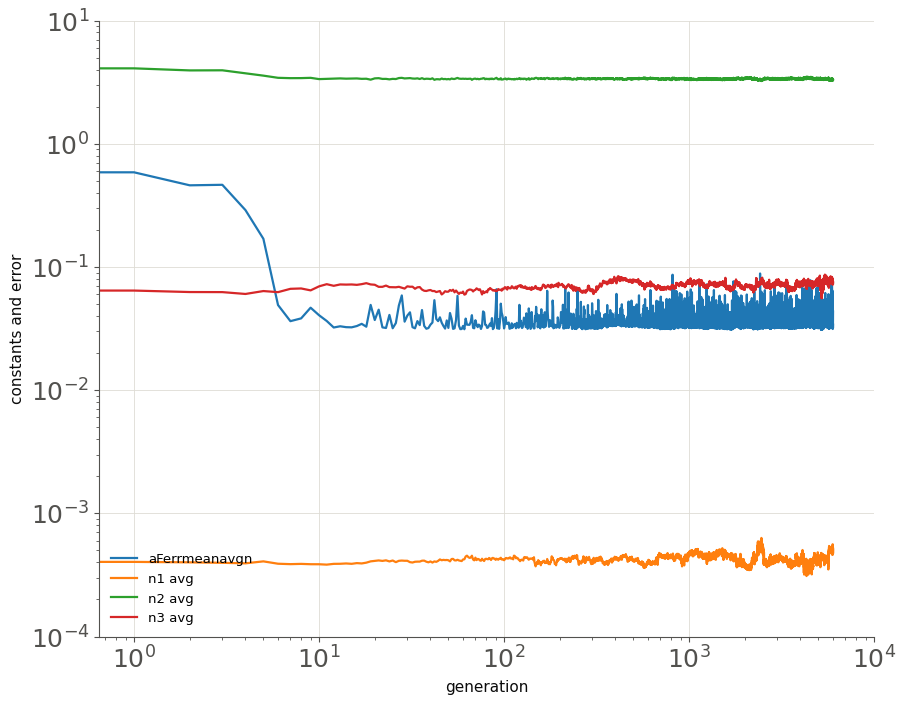

In [4]:
'''Task 2.2 - first run with the initial guesses of the skeleton code (n1i = 0.00027, n2i = 4.0,
   n3i = 0.063), the skeleton mutation amplitude (+/-8.5 %) and NGEN = 6000, followed by the
   skeleton plot of the evolution of the population-average constants and error'''
r0 = run_GA(0.00027, 4.0, 0.063, NGEN=6000, MUT=0.085, rseed=1)

plt.rcParams.update({'font.size': 18})
plt.figure(figsize=[10, 8])
plt.plot(r0['gen'], r0['aFerrmeanavgn'])
plt.plot(r0['gen'], r0['n1avg'])
plt.plot(r0['gen'], r0['n2avg'])
plt.plot(r0['gen'], r0['n3avg'])
plt.legend(['aFerrmeanavgn', 'n1 avg', 'n2 avg', 'n3 avg'], loc='lower left')
plt.xlabel('generation')
plt.ylabel('constants and error')
plt.loglog()
plt.yticks([0.0001, 0.001, 0.01, 0.1, 1.0, 10])
plt.xticks([1, 10, 100, 1000, 10000])
plt.show()
plt.rcParams.update({'font.size': 11})


In [5]:
'''(added) independent check: deterministic minimisation (scipy Nelder-Mead, multi-start) of the SAME
   objective [Ferr]mean = (1/ND) sum |ln n1 + n2 ln(Tw-Tsat) + n3 ln g - ln q"| / |ln q"|  (Eq. 1.4).
   It is only used to judge how close the genetic-algorithm constants are to the true minimum.'''
from scipy.optimize import minimize
Y = numpy.array(ydata)
lq, ldT, lg = numpy.log(Y[:, 0]), numpy.log(Y[:, 1]), numpy.log(Y[:, 2])

def Fmean3(n1, n2, n3):
    return numpy.mean(numpy.abs(-lq + numpy.log(n1) + n2 * ldT + n3 * lg) / numpy.abs(lq))

best = None
for x0 in [(-6., 3., 0.05), (-8., 3.5, 0.1), (-4., 2.5, 0.0), (-3., 2., 0.2)]:
    rr = minimize(lambda x: Fmean3(math.exp(x[0]), x[1], x[2]), x0, method='Nelder-Mead',
                  options=dict(xatol=1e-10, fatol=1e-13, maxiter=20000))
    if best is None or rr.fun < best.fun:
        best = rr
ref3 = dict(n1=math.exp(best.x[0]), n2=best.x[1], n3=best.x[2], F=best.fun)
print('reference minimum: n1 = %.5e  n2 = %.4f  n3 = %.4f   [Ferr]mean = %.5f' % (ref3['n1'], ref3['n2'], ref3['n3'], ref3['F']))


reference minimum: n1 = 1.50843e-03  n2 = 3.0103  n3 = 0.0464   [Ferr]mean = 0.02869


In [6]:
'''Task 2.2 - effect of the initial guesses, of the maximum mutation amplitude MUT and of NGEN.
   4 sets of initial guesses x 3 mutation amplitudes x 5 random seeds (NGEN = 6000), plus
   longer runs (NGEN = 20000) and a two-stage strategy (MUT = 0.40 then MUT = 0.03 restarted
   from the stage-1 best constants).'''
import time
SETS22 = {'Set 1': (0.00027, 4.0, 0.063),    # skeleton code values
          'Set 2': (0.001, 3.0, 0.05),       # physics: q" ~ (Tw-Tsat)^3, q" ~ g^n with 0.01 < n < 0.1
          'Set 3': (0.01, 2.0, 0.25),        # far: weaker superheat exponent, n3 = 0.25 (pure-fluid, g/gen > 0.1)
          'Set 4': (1.0e-6, 5.0, 0.01)}      # very far: n1 1500 times too small, n2 = 5
MUTS22 = [0.085, 0.20, 0.40]
SEEDS = [1, 2, 3, 4, 5]
FNEAR = 1.01 * ref3['F']          # 'near-optimal' threshold (1 % above the true minimum)

def summary(r, **kw):
    d = dict(F=r['aFerrmeanavgnMin'], n1=r['n1min'], n2=r['n2min'], n3=r['n3min'], kmin=r['kmin'],
             k035=first_below(r['aFerrmeanavgn'], 0.035), knear=first_below(r['aFerrmeanavgn'], FNEAR),
             Fend=r['aFerrend'], nkeep_mean=float(numpy.mean(r['nkeephist'])),
             nkeep0=float(numpy.mean(numpy.array(r['nkeephist']) == 0)))
    d.update(kw)
    return d

t0 = time.time()
study22 = []
for name, init in SETS22.items():
    for MUT in MUTS22:
        for s in SEEDS:
            r = run_GA(*init, NGEN=6000, MUT=MUT, rseed=s, verbose=False)
            study22.append(summary(r, set=name, init=init, MUT=MUT, NGEN=6000, seed=s, mode='single'))
    # longer runs with the skeleton mutation amplitude
    for s in SEEDS[:2]:
        r = run_GA(*init, NGEN=20000, MUT=0.085, rseed=s, verbose=False)
        study22.append(summary(r, set=name, init=init, MUT=0.085, NGEN=20000, seed=s, mode='single'))
    # two-stage strategy: exploration with large mutations, then refinement with small mutations
    for s in SEEDS:
        r1 = run_GA(*init, NGEN=6000, MUT=0.40, rseed=s, verbose=False)
        r2 = run_GA(r1['n1min'], r1['n2min'], r1['n3min'], NGEN=6000, MUT=0.03, rseed=100 + s, verbose=False)
        d = summary(r2, set=name, init=init, MUT='0.40/0.03', NGEN='6000+6000', seed=s, mode='two-stage')
        if r1['aFerrmeanavgnMin'] < d['F']:           # keep stage 1 result if stage 2 did not improve it
            d.update(F=r1['aFerrmeanavgnMin'], n1=r1['n1min'], n2=r1['n2min'], n3=r1['n3min'])
        d['k035'] = first_below(r1['aFerrmeanavgn'], 0.035)
        study22.append(d)
print('study: %d runs in %.0f s' % (len(study22), time.time() - t0))

# summary table: one line per (set, MUT, NGEN)
print('\n%-6s %-10s %-9s | %-8s %-8s %-8s | %-5s | %-6s | %-9s %-7s %-7s' % ('set', 'MUT', 'NGEN', 'Fbest', 'Fmedian', 'Fworst', '<.035', 'k035', 'n1', 'n2', 'n3'))
table22 = []
for name in SETS22:
    for key in [(m, 6000) for m in MUTS22] + [(0.085, 20000), ('0.40/0.03', '6000+6000')]:
        runs = [d for d in study22 if d['set'] == name and d['MUT'] == key[0] and d['NGEN'] == key[1]]
        Fs = numpy.array([d['F'] for d in runs])
        b = runs[int(numpy.argmin(Fs))]
        ks = [d['k035'] for d in runs if d['k035'] >= 0]
        row = dict(set=name, init=SETS22[name], MUT=key[0], NGEN=key[1], nruns=len(runs), Fbest=float(Fs.min()),
                   Fmed=float(numpy.median(Fs)), Fworst=float(Fs.max()), nsucc=int((Fs < 0.035).sum()),
                   k035med=float(numpy.median(ks)) if ks else -1, n1=b['n1'], n2=b['n2'], n3=b['n3'],
                   n2min=float(min(d['n2'] for d in runs)), n2max=float(max(d['n2'] for d in runs)),
                   nkeep0=float(numpy.mean([d['nkeep0'] for d in runs])), seed=b['seed'])
        table22.append(row)
        print('%-6s %-10s %-9s | %.5f  %.5f  %.5f | %d/%d   | %6s | %.3e %.4f  %.4f' % (name, key[0], key[1], row['Fbest'], row['Fmed'], row['Fworst'],
              row['nsucc'], row['nruns'], '%d' % row['k035med'] if ks else 'never', row['n1'], row['n2'], row['n3']))


study: 88 runs in 319 s

set    MUT        NGEN      | Fbest    Fmedian  Fworst   | <.035 | k035   | n1        n2      n3     
Set 1  0.085      6000      | 0.02931  0.02964  0.03084 | 5/5   |     12 | 1.162e-03 3.0846  0.0588
Set 1  0.2        6000      | 0.02872  0.02878  0.02901 | 5/5   |      6 | 1.590e-03 2.9967  0.0456
Set 1  0.4        6000      | 0.02881  0.02903  0.02921 | 5/5   |      6 | 1.367e-03 3.0373  0.0462
Set 1  0.085      20000     | 0.02884  0.02958  0.03032 | 2/2   |     56 | 1.340e-03 3.0456  0.0515
Set 1  0.40/0.03  6000+6000 | 0.02870  0.02883  0.02892 | 5/5   |      6 | 1.491e-03 3.0136  0.0466
Set 2  0.085      6000      | 0.02877  0.02880  0.02898 | 5/5   |      2 | 1.435e-03 3.0235  0.0462
Set 2  0.2        6000      | 0.02871  0.02875  0.02884 | 5/5   |      4 | 1.497e-03 3.0124  0.0462
Set 2  0.4        6000      | 0.02877  0.02883  0.02925 | 5/5   |      6 | 1.473e-03 3.0171  0.0486
Set 2  0.085      20000     | 0.02879  0.02880  0.02881 | 2/2   |      2 

best run of the study: Set 2 (0.001, 3.0, 0.05) MUT = 0.40/0.03 NGEN = 6000+6000 seed = 2


ENDING: pop. avg n1-n3,aFerrmean: 0.0017552119796215321 2.96391764455471 0.043301941231471956 0.02909208963689504
MINUMUM:  avg n1-n3,aFerrmeanMin: 0.0017176763010409506 2.9747447207481357 0.04381909553826206 0.028701911289596944  at generation 966
TIME AVG:    avg n1-n3,aFerrmean: 0.0017728768801530403 2.9599808363622406 0.04272261070811415 0.030152033626312472

BEST FIT (Eq. 1.1):  n1 = 1.71768e-03   n2 = 2.9747   n3 = 0.0438   [Ferr]mean,min = 0.02870
reference minimum :  n1 = 1.50843e-03   n2 = 3.0103   n3 = 0.0464   [Ferr]mean     = 0.02869


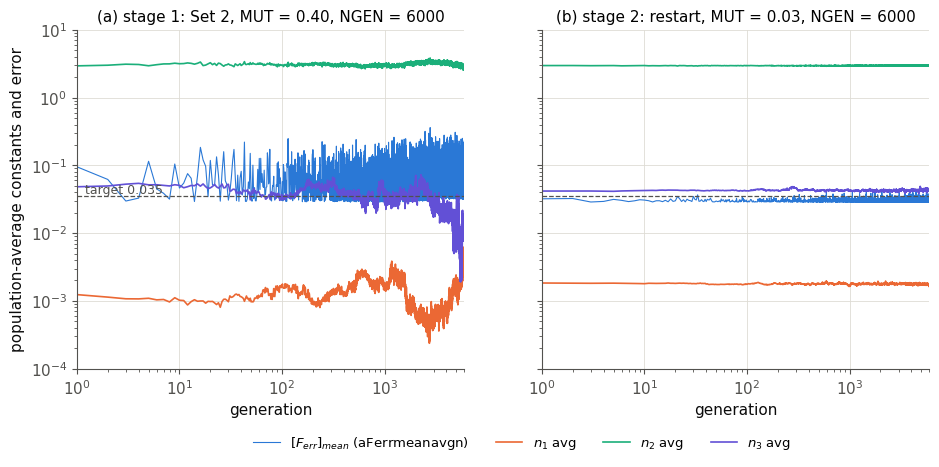


rms deviation of q"exp from q"pred       = 23.12 W/cm2 (mean q" = 113.2 W/cm2)
rms fractional deviation (q"exp-q"pred)/q"pred = 0.1663
mean absolute fractional deviation      = 0.1319
max absolute fractional deviation       = 0.3296
fraction of points within +/-10 %       = 0.47
group g = 0.098 : mean deviation -0.018   rms deviation 0.075   (18 points)
group g = 9.800 : mean deviation -0.192   rms deviation 0.202   (11 points)
group g = 19.600 : mean deviation +0.157   rms deviation 0.208   (16 points)


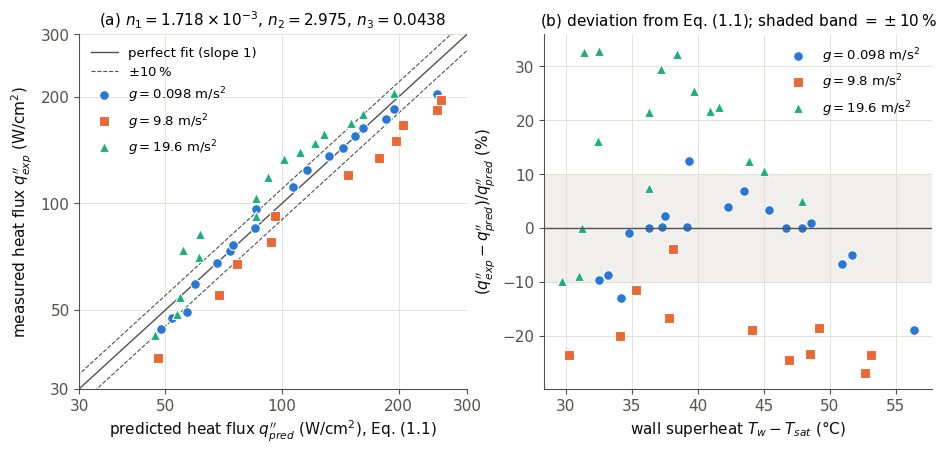

In [7]:
'''Task 2.2 - best fit: the run of the study with the lowest minimum error is replayed (same seed,
   so it is reproduced exactly) to obtain its histories, then the constants n1min, n2min, n3min are
   used for the plots and the deviation statistics.'''
bestrun = min(study22, key=lambda d: d['F'])
print('best run of the study:', bestrun['set'], bestrun['init'], 'MUT =', bestrun['MUT'], 'NGEN =', bestrun['NGEN'], 'seed =', bestrun['seed'])
if bestrun['mode'] == 'single':
    rb = run_GA(*bestrun['init'], NGEN=bestrun['NGEN'], MUT=bestrun['MUT'], rseed=bestrun['seed'])
    hist = rb
else:
    r1 = run_GA(*bestrun['init'], NGEN=6000, MUT=0.40, rseed=bestrun['seed'], verbose=False)
    r2 = run_GA(r1['n1min'], r1['n2min'], r1['n3min'], NGEN=6000, MUT=0.03, rseed=100 + bestrun['seed'])
    rb = r1 if r1['aFerrmeanavgnMin'] < r2['aFerrmeanavgnMin'] else r2
n1min, n2min, n3min, Fmin = rb['n1min'], rb['n2min'], rb['n3min'], rb['aFerrmeanavgnMin']
print('\nBEST FIT (Eq. 1.1):  n1 = %.5e   n2 = %.4f   n3 = %.4f   [Ferr]mean,min = %.5f' % (n1min, n2min, n3min, Fmin))
print('reference minimum :  n1 = %.5e   n2 = %.4f   n3 = %.4f   [Ferr]mean     = %.5f' % (ref3['n1'], ref3['n2'], ref3['n3'], ref3['F']))

# evolution of the population-average constants and error (skeleton plot, report style)
def evolution_plot(ax, h, title):
    g = numpy.arange(1, len(h['aFerrmeanavgn']) + 1)
    ax.plot(g, h['aFerrmeanavgn'], color=C[0], lw=0.8, label=r'$[F_{err}]_{mean}$ (aFerrmeanavgn)')
    ax.plot(g, h['n1avg'], color=C[1], lw=1.2, label=r'$n_1$ avg')
    ax.plot(g, h['n2avg'], color=C[2], lw=1.2, label=r'$n_2$ avg')
    ax.plot(g, h['n3avg'], color=C[6], lw=1.2, label=r'$n_3$ avg')
    ax.axhline(0.035, color=INK2, ls='--', lw=0.9)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1, len(g)); ax.set_ylim(1e-4, 10)
    ax.set_xlabel('generation'); ax.set_title(title)
if bestrun['mode'] == 'single':
    fig, ax = plt.subplots(figsize=(6.4, 4.6)); axs = [ax]
    evolution_plot(ax, hist, '%s, MUT = %s, seed %d' % (bestrun['set'], bestrun['MUT'], bestrun['seed']))
else:
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
    evolution_plot(axs[0], r1, '(a) stage 1: %s, MUT = 0.40, NGEN = 6000' % bestrun['set'])
    evolution_plot(axs[1], r2, '(b) stage 2: restart, MUT = 0.03, NGEN = 6000')
axs[0].set_ylabel('population-average constants and error')
axs[0].text(1.2, 0.038, 'target 0.035', color=INK2, fontsize=9)
axs[-1].legend(loc='upper center', bbox_to_anchor=(-0.05 if len(axs) > 1 else 0.5, -0.16), ncol=4)
savefig('t22_evolution')

# predicted vs measured heat flux + deviation statistics
qpppred = [n1min * (ydata[i][1]**n2min) * ((ydata[i][2])**n3min) for i in range(ND)]
qppdata = [ydata[i][0] for i in range(ND)]
qp, qd = numpy.array(qpppred), numpy.array(qppdata)
dev = (qd - qp) / qp                                  # fractional deviation of data from prediction
stats22 = dict(rms_abs=float(numpy.sqrt(numpy.mean((qd - qp)**2))), rms_rel=float(numpy.sqrt(numpy.mean(dev**2))),
               mean_abs_rel=float(numpy.mean(numpy.abs(dev))), max_abs_rel=float(numpy.max(numpy.abs(dev))),
               within10=float(numpy.mean(numpy.abs(dev) <= 0.10)), mean_q=float(qd.mean()))
print('\nrms deviation of q"exp from q"pred       = %.2f W/cm2 (mean q" = %.1f W/cm2)' % (stats22['rms_abs'], stats22['mean_q']))
print('rms fractional deviation (q"exp-q"pred)/q"pred = %.4f' % stats22['rms_rel'])
print('mean absolute fractional deviation      = %.4f' % stats22['mean_abs_rel'])
print('max absolute fractional deviation       = %.4f' % stats22['max_abs_rel'])
print('fraction of points within +/-10 %%       = %.2f' % stats22['within10'])

groups22 = [(0.098, r'$g = 0.098$ m/s$^2$'), (9.8, r'$g = 9.8$ m/s$^2$'), (19.6, r'$g = 19.6$ m/s$^2$')]
bias22 = {}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
xx = numpy.array([10, 1000])
a1.plot(xx, xx, '-', color=INK2, lw=1, label='perfect fit (slope 1)')
a1.plot(xx, 1.1 * xx, '--', color=INK2, lw=0.8, label=r'$\pm 10\,\%$')
a1.plot(xx, 0.9 * xx, '--', color=INK2, lw=0.8)
for c, (gv, lab) in enumerate(groups22):
    sel = numpy.array([ydata[i][2] == gv for i in range(ND)])
    a1.loglog(qp[sel], qd[sel], MK[c], color=C[c], ms=7, mec='white', mew=0.8, label=lab)
    a2.plot(Y[sel, 1], 100 * dev[sel], MK[c], color=C[c], ms=7, mec='white', mew=0.8, label=lab)
    bias22[str(gv)] = dict(mean_dev=float(dev[sel].mean()), rms_dev=float(numpy.sqrt(numpy.mean(dev[sel]**2))), n=int(sel.sum()))
    print('group g = %5.3f : mean deviation %+.3f   rms deviation %.3f   (%d points)' % (gv, dev[sel].mean(), numpy.sqrt(numpy.mean(dev[sel]**2)), sel.sum()))
a1.set_xlim(30, 300); a1.set_ylim(30, 300)
plain_log_ticks(a1, [30, 50, 100, 200, 300], [30, 50, 100, 200, 300])
a1.set_xlabel(r'predicted heat flux $q^{\prime\prime}_{pred}$ (W/cm$^2$), Eq. (1.1)')
a1.set_ylabel(r'measured heat flux $q^{\prime\prime}_{exp}$ (W/cm$^2$)')
a1.set_title(r'(a) $n_1=%s$, $n_2=%.3f$, $n_3=%.4f$' % (sci(n1min, 3), n2min, n3min))
a1.legend(loc='upper left')
a2.axhspan(-10, 10, color='#f0efec', zorder=0)
a2.axhline(0, color=INK2, lw=1)
a2.set_xlabel(r'wall superheat $T_w - T_{sat}$ (°C)')
a2.set_ylabel(r'$(q^{\prime\prime}_{exp}-q^{\prime\prime}_{pred})/q^{\prime\prime}_{pred}$ (%)')
a2.set_title(r'(b) deviation from Eq. (1.1); shaded band $=\pm 10\,\%$')
a2.legend(loc='upper right')
savefig('t22_parity')

json.dump(dict(best=dict(n1=n1min, n2=n2min, n3=n3min, F=Fmin, set=bestrun['set'], init=bestrun['init'], MUT=bestrun['MUT'],
                         NGEN=bestrun['NGEN'], seed=bestrun['seed'], mode=bestrun['mode'], kmin=rb['kmin'],
                         n1end=rb['n1end'], n2end=rb['n2end'], n3end=rb['n3end'], Fend=rb['aFerrend'],
                         n1ta=rb['n1ta'], n2ta=rb['n2ta'], n3ta=rb['n3ta'], Fta=rb['aFerrta']),
               base=dict(n1=r0['n1min'], n2=r0['n2min'], n3=r0['n3min'], F=r0['aFerrmeanavgnMin'], kmin=r0['kmin'],
                         n1end=r0['n1end'], n2end=r0['n2end'], n3end=r0['n3end'], Fend=r0['aFerrend'],
                         n1ta=r0['n1ta'], n2ta=r0['n2ta'], n3ta=r0['n3ta'], Fta=r0['aFerrta'], k035=first_below(r0['aFerrmeanavgn'], 0.035)),
               ref=ref3, stats=stats22, bias=bias22, table=table22, runs=study22),
          open(RESDIR + 'task22.json', 'w'), indent=1)


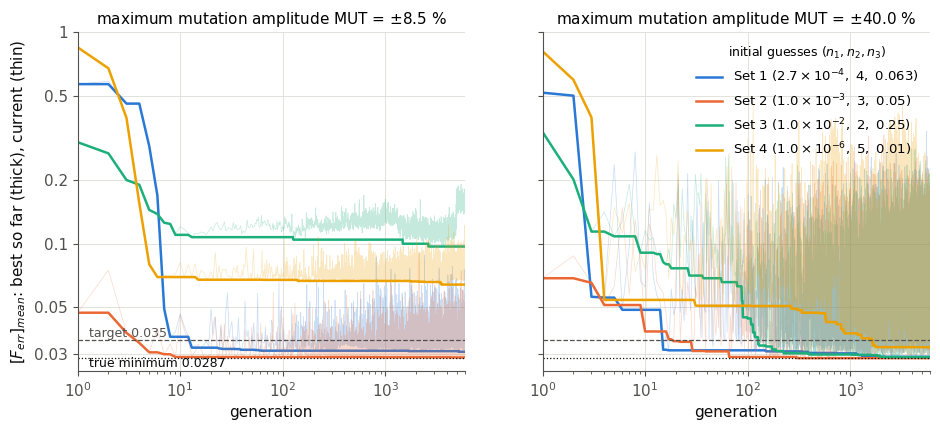

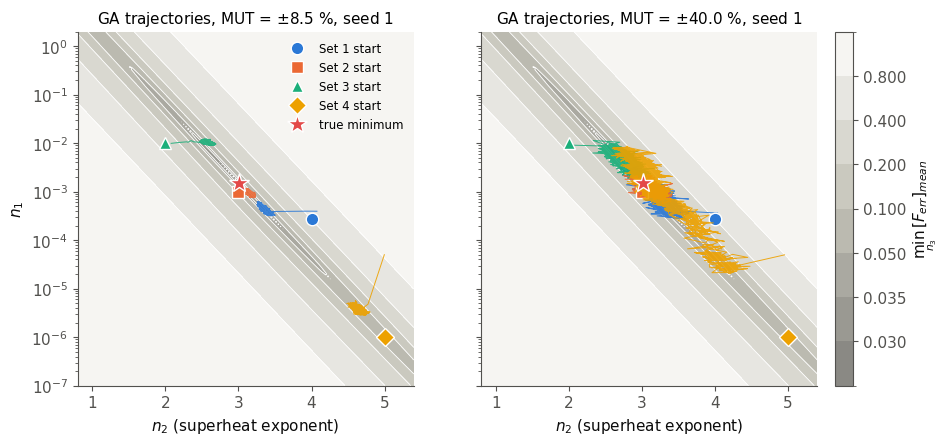

In [8]:
'''Task 2.2 - convergence histories of the 4 sets of initial guesses (seed 1) for the skeleton
   mutation amplitude (MUT = 0.085) and for MUT = 0.40, and trajectories of the population-average
   constants on the error landscape (min over n3 of [Ferr]mean in the (n2, n1) plane).'''
traj = {}
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for a, MUT in zip(axs, [0.085, 0.40]):
    for c, (name, init) in enumerate(SETS22.items()):
        r = run_GA(*init, NGEN=6000, MUT=MUT, rseed=1, verbose=False)
        traj[(name, MUT)] = (numpy.array(r['n1avg']), numpy.array(r['n2avg']))
        g = numpy.arange(1, 6001)
        a.plot(g, r['aFerrmeanavgn'], color=C[c], lw=0.5, alpha=0.25)
        a.plot(g, best_so_far(r['aFerrmeanavgn']), color=C[c], lw=1.8,
               label='%s $(%s,\\ %.3g,\\ %.3g)$' % (name, sci(init[0], 1), init[1], init[2]))
    a.axhline(0.035, color=INK2, ls='--', lw=0.9)
    a.axhline(ref3['F'], color=INK, ls=':', lw=0.9)
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlim(1, 6000); a.set_ylim(0.025, 1)
    plain_log_ticks(a, None, [0.03, 0.05, 0.1, 0.2, 0.5, 1])
    a.set_xlabel('generation')
    a.set_title('maximum mutation amplitude MUT = $\\pm$%.1f %%' % (100 * MUT))
axs[0].set_ylabel(r'$[F_{err}]_{mean}$: best so far (thick), current (thin)')
axs[0].text(1.3, 0.0362, 'target 0.035', color=INK2, fontsize=9)
axs[0].text(1.3, 0.0262, 'true minimum %.4f' % ref3['F'], color=INK, fontsize=9)
axs[1].legend(loc='upper right', title=r'initial guesses $(n_1,n_2,n_3)$', title_fontsize=9)
savefig('t22_convergence')

# error landscape: for each (n1, n2) take the minimum over n3 of [Ferr]mean
N1g = numpy.logspace(-7, 0.3, 150)
N2g = numpy.linspace(0.8, 5.4, 150)
N3g = numpy.linspace(-0.1, 1.0, 111)
L1, L2, L3 = numpy.meshgrid(numpy.log(N1g), N2g, N3g, indexing='ij')
E = numpy.zeros(L1.shape)
for i in range(ND):
    E += numpy.abs(-lq[i] + L1 + L2 * ldT[i] + L3 * lg[i]) / abs(lq[i])
Fgrid = (E / ND).min(axis=2)
lev = [0.0, 0.03, 0.035, 0.05, 0.1, 0.2, 0.4, 0.8, 10]
GRAYS = LinearSegmentedColormap.from_list('grays', ['#8a8984', '#c3c2b7', '#f6f5f2'])   # dark = low error
norm = mpl.colors.BoundaryNorm(lev, GRAYS.N)
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
for a, MUT in zip(axs, [0.085, 0.40]):
    cs = a.contourf(N2g, N1g, Fgrid, levels=lev, cmap=GRAYS, norm=norm)
    a.contour(N2g, N1g, Fgrid, levels=lev[1:-1], colors='white', linewidths=0.6)
    for c, name in enumerate(SETS22):
        n1h, n2h = traj[(name, MUT)]
        a.plot(n2h[::3], n1h[::3], '-', color=C[c], lw=0.7, alpha=0.9)
        a.plot(SETS22[name][1], SETS22[name][0], MK[c], color=C[c], ms=9, mec='white', mew=1, label=name + ' start')
    a.plot(ref3['n2'], ref3['n1'], '*', color=C[7], ms=15, mec='white', label='true minimum')
    a.set_yscale('log'); a.set_xlim(0.8, 5.4); a.set_ylim(1e-7, 2)
    a.set_xlabel(r'$n_2$ (superheat exponent)')
    a.set_title('GA trajectories, MUT = $\\pm$%.1f %%, seed 1' % (100 * MUT))
    a.grid(False)
axs[0].set_ylabel(r'$n_1$')
axs[0].legend(loc='upper right', fontsize=8.5)
cb = fig.colorbar(cs, ax=axs, ticks=lev[1:-1], pad=0.02)
cb.set_label(r'$\min_{n_3}\,[F_{err}]_{mean}$')
savefig('t22_landscape')
